# FSPL example (host + JAX kernel)

Finite-source point-lens photometry and astrometry from `bagle.model`, compared to the matching point-source (`PSPL`) models.

**Units**
- Phot-only: `radiusS` in Einstein radii.
- Phot+astrom: `radiusS` in arcsec.

Milestone (b): host AMG figures, plus a check that the JAX Bozza contour kernel in `bagle.jax.fspl` matches host amplification. Milestone (c): traced `jax_log_likely_*` / `fspl_photometry` overlay on the light curve.

In [26]:
%matplotlib inline
from bagle import model
import numpy as np
import matplotlib.pyplot as plt

## Phot+astrom parameters

Impact parameter below `rho` so the finite-source effect is visible near peak.

| Param | Value | Units |
|---|---|---|
| $m_L$ | 10 | $M_\odot$ |
| $t_0$ | 57000 | MJD |
| $\beta$ | 0.15 | mas |
| $d_L$ | 4000 | pc |
| $d_L/d_S$ | 0.5 | |
| $radiusS$ | $4\times10^{-4}$ | arcsec |
| $b_{sff}$ | 1.0 | |
| $mag_{src}$ | 18 | |

In [33]:
mL = 10.0
t0 = 57000.0
beta = 0.15  # mas; keep |u0| < rho near peak
dL = 4000.0
dL_dS = 0.5
xS0_E, xS0_N = 0.0, 0.0
muL_E, muL_N = 0.0, 0.0
muS_E, muS_N = 3.0, 0.0
radiusS = 4e-4  # arcsec
b_sff = [1.0]
mag_src = [18.0]
n_outline = 200

fspl = model.FSPL_PhotAstrom_noPar_Param1(
    mL, t0, beta, dL, dL_dS,
    xS0_E, xS0_N, muL_E, muL_N, muS_E, muS_N,
    radiusS, b_sff, mag_src, n_outline=n_outline,
)
pspl = model.PSPL_PhotAstrom_noPar_Param1(
    mL, t0, beta, dL, dL_dS,
    xS0_E, xS0_N, muL_E, muL_N, muS_E, muS_N,
    b_sff, mag_src,
)

rho = fspl.radiusS * 1e3 / fspl.thetaE_amp
print(f"thetaE = {fspl.thetaE_amp:.3f} mas, u0 = {fspl.u0_amp:.3f}, rho = {rho:.3f}, tE = {fspl.tE:.1f} d")

t = np.linspace(t0 - 1.5 * fspl.tE, t0 + 1.5 * fspl.tE, 600)

thetaE = 3.191 mas, u0 = 0.047, rho = 0.125, tE = 388.5 d


### 1. Light curve

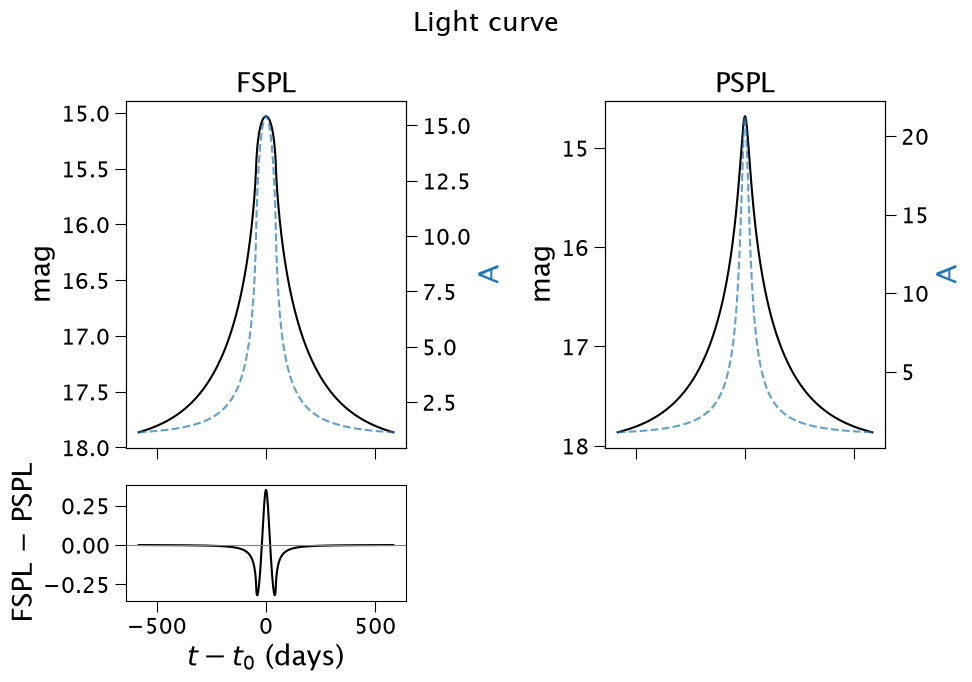

In [34]:
mag_f = fspl.get_photometry(t)
mag_p = pspl.get_photometry(t)
amp_f = fspl.get_amplification(t)
amp_p = pspl.get_amplification(t)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex='col',
                         gridspec_kw=dict(height_ratios=[3, 1]))
for ax, mag, amp, title in (
    (axes[0, 0], mag_f, amp_f, 'FSPL'),
    (axes[0, 1], mag_p, amp_p, 'PSPL'),
):
    ax.plot(t - t0, mag, 'k-')
    ax.set_ylabel('mag')
    ax.invert_yaxis()
    ax.set_title(title)
    ax2 = ax.twinx()
    ax2.plot(t - t0, amp, 'C0--', alpha=0.7)
    ax2.set_ylabel('A', color='C0')
axes[1, 0].plot(t - t0, mag_f - mag_p, 'k-')
axes[1, 0].axhline(0, color='0.5', lw=0.8)
axes[1, 0].set_ylabel('FSPL − PSPL')
axes[1, 0].set_xlabel(r'$t - t_0$ (days)')
axes[1, 1].axis('off')
fig.suptitle('Light curve')
fig.tight_layout()
plt.show()

### JAX Bozza kernel check (milestone b2)

Static-`n_outline` contour in `bagle.jax.fspl` vs host `get_amplification` on the same trajectory.

JAX vs host amp: max rel = 8.707e-04 (n_outline=200)


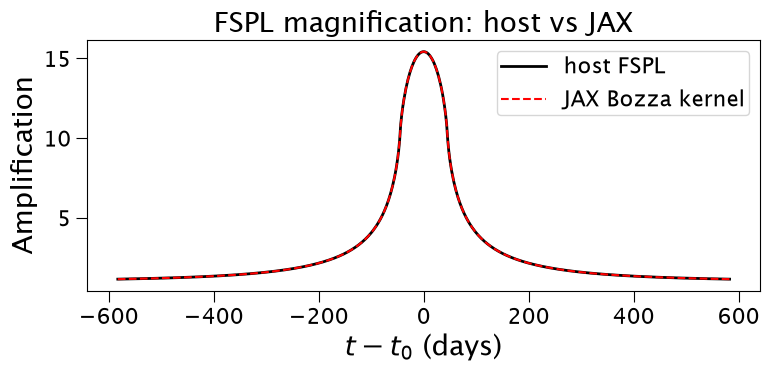

In [35]:
from bagle.jax import fspl as fspl_jax

rho = fspl.source_radius_thetaE_units()
u = fspl.get_u(t)
mag_jax, _cent = fspl_jax.fspl_magnification_centroid(u, rho, n_outline)
mag_jax = np.asarray(mag_jax)
mag_host = np.asarray(amp_f)

rel = np.max(np.abs(mag_jax - mag_host) / np.maximum(np.abs(mag_host), 1e-30))
print(f"JAX vs host amp: max rel = {rel:.3e} (n_outline={n_outline})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t - t0, mag_host, 'k-', lw=2, label='host FSPL')
ax.plot(t - t0, mag_jax, 'r--', lw=1.5, label='JAX Bozza kernel')
ax.set_xlabel(r'$t - t_0$ (days)')
ax.set_ylabel('Amplification')
ax.legend()
ax.set_title('FSPL magnification: host vs JAX')
plt.tight_layout()
plt.show()

### Traced photometry overlay (milestone c)

`FSPL_PhotAstromParam1.jax_log_likely_photometry` uses the same Bozza kernel through `fspl_photometry`. Overlay the traced magnitudes on the host light curve.

JAX-traced vs host mag: max rel = 6.097e-05
jax_log_likely_photometry = 1795.828


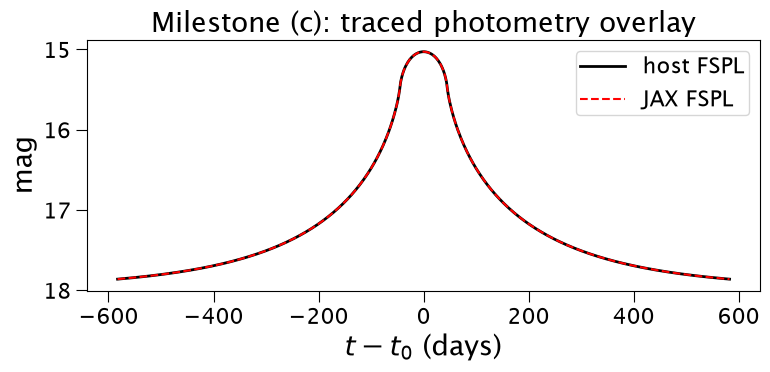

In [36]:
from bagle import model_jax
from bagle.jax.fspl import fspl_photometry

# Physical Param1 geometry → Einstein-frame trajectory for the traced path.
p1 = model_jax.FSPL_PhotAstromParam1
b0 = float(np.asarray(b_sff).ravel()[0])
m0 = float(np.asarray(mag_src).ravel()[0])
vec = np.array([
    mL, t0, beta, dL, dL_dS, xS0_E, xS0_N,
    muL_E, muL_N, muS_E, muS_N, radiusS, b0, m0,
], dtype=float)
_p, geom = p1._jax_geometry(vec)
(u0, thetaE_hat, tE_j, _piE_E, _piE_N, _xS0, _xL0, _muS, _muL,
 thetaE, _piS, _piL) = geom
rho_j = float(radiusS) * 1e3 / float(thetaE)

mag_traced = np.asarray(fspl_photometry(
    t, t0, tE_j, u0, thetaE_hat, rho_j, n_outline, m0, b0,
))
mag_host = np.asarray(mag_f)
rel_mag = np.max(np.abs(mag_traced - mag_host) / np.maximum(np.abs(mag_host), 1e-30))
print(f"JAX-traced vs host mag: max rel = {rel_mag:.3e}")

# Smoke the classmethod log-likelihood at the host photometry.
lnL = float(p1.jax_log_likely_photometry(
    vec, t, mag_host, np.full_like(t, 0.02), b0, m0,
    n_outline=n_outline,
))
print(f"jax_log_likely_photometry = {lnL:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t - t0, mag_host, 'k-', lw=2, label='host FSPL')
ax.plot(t - t0, mag_traced, 'r--', lw=1.5, label='JAX FSPL')
ax.set_xlabel(r'$t - t_0$ (days)')
ax.set_ylabel('mag')
ax.invert_yaxis()
ax.legend()
ax.set_title('Milestone (c): traced photometry overlay')
plt.tight_layout()
plt.show()

### 2. Unlensed astrometry

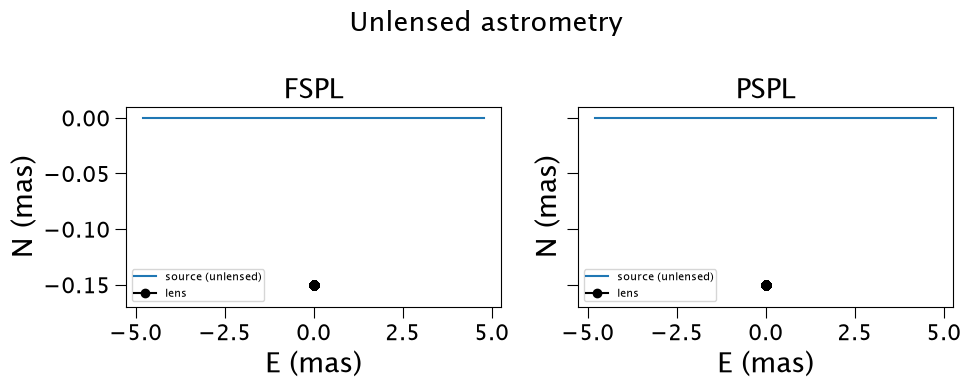

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, mod, title in ((axes[0], fspl, 'FSPL'), (axes[1], pspl, 'PSPL')):
    xS = mod.get_astrometry_unlensed(t)
    xL = mod.get_lens_astrometry(t)
    ax.plot(xS[:, 0] * 1e3, xS[:, 1] * 1e3, 'C0-', label='source (unlensed)')
    ax.plot(xL[:, 0] * 1e3, xL[:, 1] * 1e3, 'k-', marker='o', label='lens')
    ax.set_xlabel('E (mas)')
    ax.set_ylabel('N (mas)')
    ax.set_title(title)
    #ax.set_aspect('equal')
    ax.legend(fontsize=8)
fig.suptitle('Unlensed astrometry')
fig.tight_layout()
plt.ylim(-0.17, 0.01)
plt.show()


### 3. Resolved astrometry (image tracks)

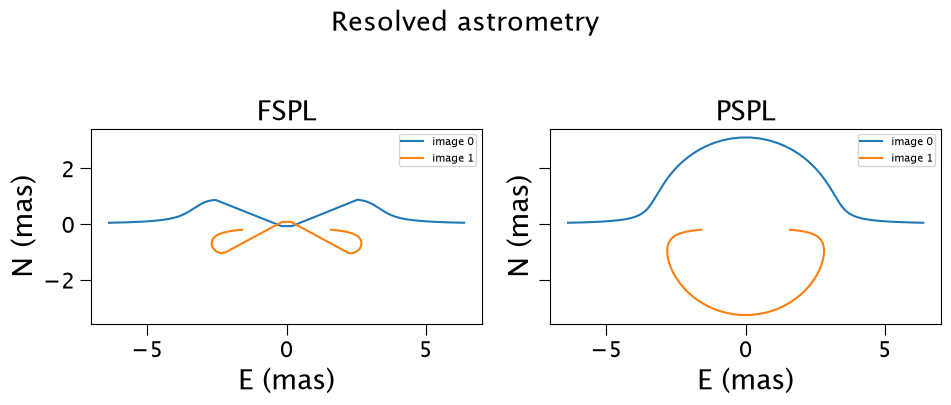

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, mod, title in ((axes[0], fspl, 'FSPL'), (axes[1], pspl, 'PSPL')):
    if hasattr(mod, 'get_resolved_astrometry'):
        # Public API: (N_t, N_sources=1, n_images, 2).
        res = np.asarray(mod.get_resolved_astrometry(t))
        for i in range(res.shape[2]):
            ax.plot(res[:, 0, i, 0] * 1e3, res[:, 0, i, 1] * 1e3, label=f'image {i}')
    ax.set_xlabel('E (mas)')
    ax.set_ylabel('N (mas)')
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.legend(fontsize=8)
fig.suptitle('Resolved astrometry')
fig.tight_layout()
plt.show()

### 4. Lensed astrometry and centroid shift

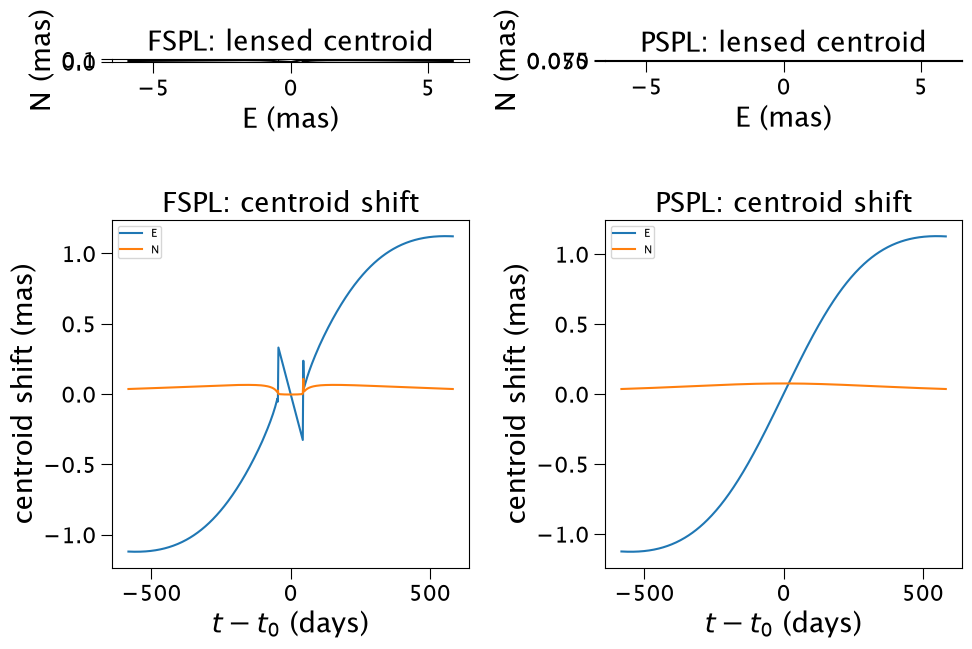

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for col, mod, title in ((0, fspl, 'FSPL'), (1, pspl, 'PSPL')):
    xS = mod.get_astrometry(t)
    shift = mod.get_centroid_shift(t)
    axes[0, col].plot(xS[:, 0] * 1e3, xS[:, 1] * 1e3, 'k-')
    axes[0, col].set_title(f'{title}: lensed centroid')
    axes[0, col].set_xlabel('E (mas)')
    axes[0, col].set_ylabel('N (mas)')
    axes[0, col].set_aspect('equal')
    axes[1, col].plot(t - t0, shift[:, 0], label='E')
    axes[1, col].plot(t - t0, shift[:, 1], label='N')
    axes[1, col].set_xlabel(r'$t - t_0$ (days)')
    axes[1, col].set_ylabel('centroid shift (mas)')
    axes[1, col].set_title(f'{title}: centroid shift')
    axes[1, col].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Phot-only leaf (light curve only)

`radiusS` is in Einstein radii.

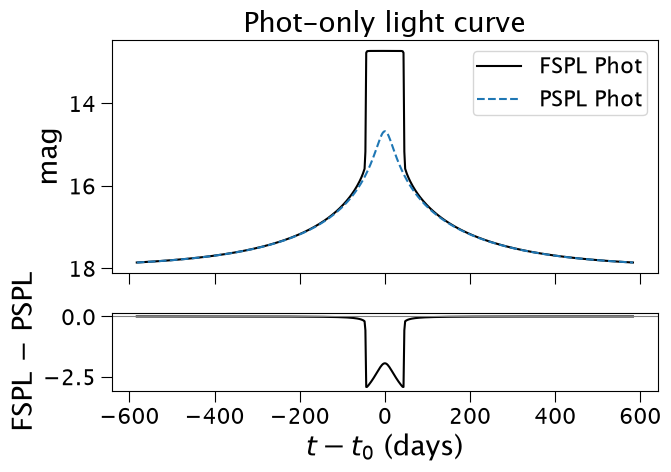

In [39]:
fspl_ph = model.FSPL_Phot_noPar_Param1(
    t0=t0, u0_amp=float(fspl.u0_amp), tE=float(fspl.tE),
    piE_E=float(fspl.piE[0]), piE_N=float(fspl.piE[1]),
    radiusS=float(rho), b_sff=b_sff, mag_src=mag_src, n_outline=n_outline,
)
pspl_ph = model.PSPL_Phot_noPar_Param1(
    t0=t0, u0_amp=float(fspl.u0_amp), tE=float(fspl.tE),
    piE_E=float(fspl.piE[0]), piE_N=float(fspl.piE[1]),
    b_sff=b_sff, mag_src=mag_src,
)

mag_f = fspl_ph.get_photometry(t)
mag_p = pspl_ph.get_photometry(t)
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True,
                         gridspec_kw=dict(height_ratios=[3, 1]))
axes[0].plot(t - t0, mag_f, 'k-', label='FSPL Phot')
axes[0].plot(t - t0, mag_p, 'C0--', label='PSPL Phot')
axes[0].invert_yaxis()
axes[0].set_ylabel('mag')
axes[0].legend()
axes[0].set_title('Phot-only light curve')
axes[1].plot(t - t0, mag_f - mag_p, 'k-')
axes[1].axhline(0, color='0.5', lw=0.8)
axes[1].set_xlabel(r'$t - t_0$ (days)')
axes[1].set_ylabel('FSPL − PSPL')
fig.tight_layout()
plt.show()